In [21]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mirichoi0218/insurance")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\HP\.cache\kagglehub\datasets\mirichoi0218\insurance\versions\1


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [23]:
df = pd.read_csv("insurance.csv")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [24]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nUnique values in categorical columns:")
for col in df.select_dtypes(include="object").columns:
    print(f"{col}: {df[col].unique()}")

Missing values in each column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Number of duplicate rows: 1

Unique values in categorical columns:
sex: ['female' 'male']
smoker: ['yes' 'no']
region: ['southwest' 'southeast' 'northwest' 'northeast']


In [25]:
# Store the original number of rows
original_rows = len(df)

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Calculate how many rows were removed
removed_rows = original_rows - len(df)

print("Original number of rows:", original_rows)
print("Duplicate rows removed:", removed_rows)
print("Rows after cleaning:", len(df))

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nRemaining duplicate rows:", df.duplicated().sum())

Original number of rows: 1338
Duplicate rows removed: 1
Rows after cleaning: 1337

Missing values after cleaning:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Remaining duplicate rows: 0


In [26]:
print("Data types:")
print(df.dtypes)

print("\nCategorical values after cleaning:")
for col in ["sex", "smoker", "region"]:
    print(f"{col}: {sorted(df[col].unique())}")

Data types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Categorical values after cleaning:
sex: ['female', 'male']
smoker: ['no', 'yes']
region: ['northeast', 'northwest', 'southeast', 'southwest']


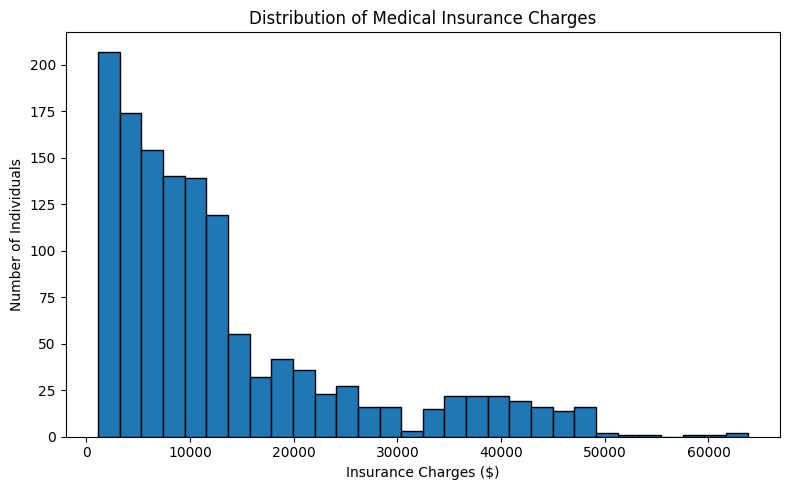

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["charges"], bins=30, edgecolor="black")

plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Insurance Charges ($)")
plt.ylabel("Number of Individuals")

plt.tight_layout()
plt.show()

<Figure size 700x500 with 0 Axes>

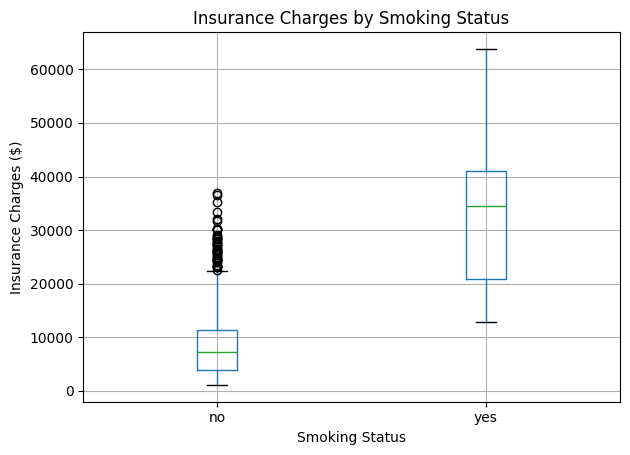

In [28]:
plt.figure(figsize=(7, 5))

df.boxplot(column="charges", by="smoker")

plt.title("Insurance Charges by Smoking Status")
plt.suptitle("")
plt.xlabel("Smoking Status")
plt.ylabel("Insurance Charges ($)")

plt.tight_layout()
plt.show()

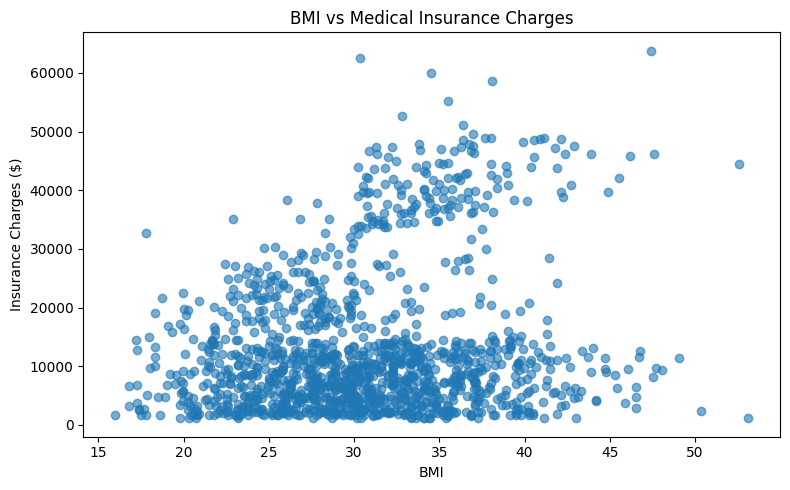

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(df["bmi"], df["charges"], alpha=0.6)

plt.title("BMI vs Medical Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges ($)")

plt.tight_layout()
plt.show()

In [30]:
X = df.drop(columns=["charges"])
y = df["charges"]

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (1337, 6)
Target: (1337,)


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1069
Testing records: 268


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical", OneHotEncoder(drop="first"), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [33]:
model.fit(X_train, y_train)

print("Multiple Linear Regression trained successfully!")

Multiple Linear Regression trained successfully!


In [34]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Charges": y_test.to_numpy(),
    "Predicted Charges": y_pred
})

display(results.head(10))

,Actual Charges,Predicted Charges
0,8688.85885,8143.693884
1,5708.86700,5737.115683
2,11436.73815,14369.314876
3,38746.35510,31745.513636
4,4463.20510,8962.386657
5,9304.70190,13149.722353
6,38511.62830,30446.760679
7,2150.46900,1453.288813
8,7345.72660,10633.018402
9,10264.44210,11318.943794


In [35]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Mean Absolute Error (MAE):  ${mae:.2f}")
print(f"Mean Squared Error (MSE):   {mse:.2f}")
print(f"Root Mean Squared Error:    ${rmse:.2f}")
print(f"R² Score:                   {r2:.4f}")

MODEL EVALUATION RESULTS
-----------------------------------
Mean Absolute Error (MAE):  $4177.05
Mean Squared Error (MSE):   35478020.68
Root Mean Squared Error:    $5956.34
R² Score:                   0.8069


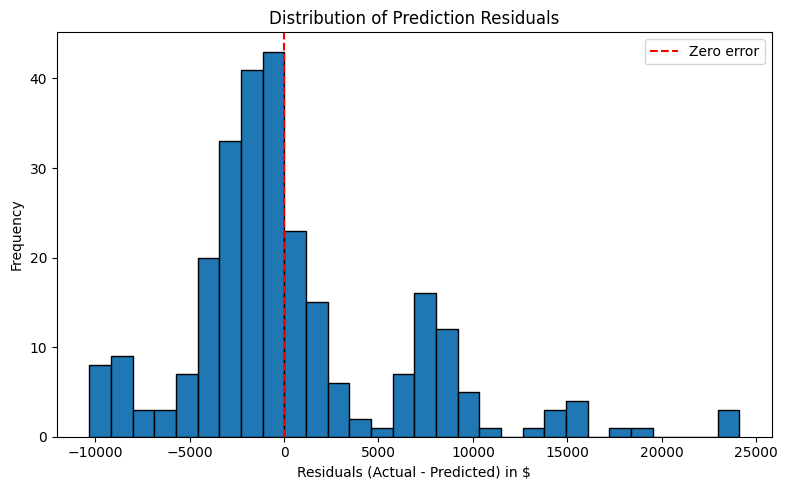

In [36]:
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, edgecolor="black")

plt.axvline(0, color="red", linestyle="--",
            label="Zero error")

plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residuals (Actual - Predicted) in $")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

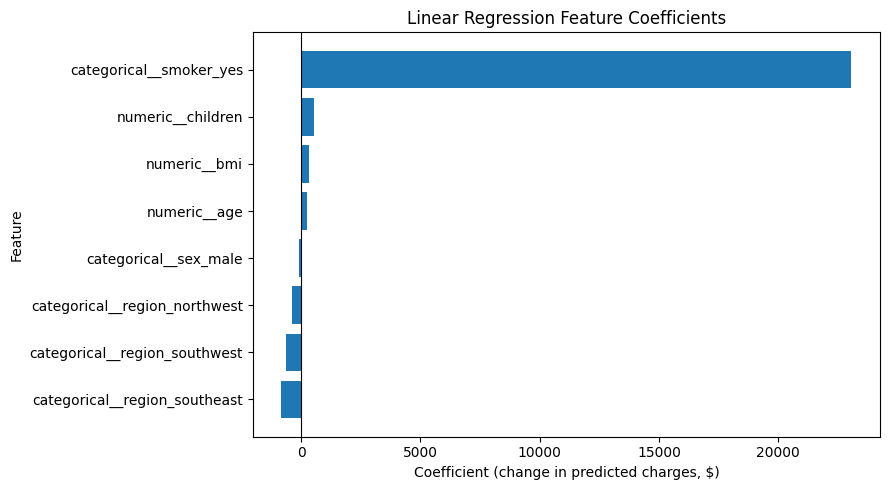

In [37]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = model.named_steps[
    "regressor"
].coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
}).sort_values("Coefficient")

plt.figure(figsize=(9, 5))

plt.barh(coef_df["Feature"], coef_df["Coefficient"])
plt.axvline(0, color="black", linewidth=0.8)

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Coefficient (change in predicted charges, $)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [38]:
final_results = pd.DataFrame({
    "Evaluation Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Value": [
        round(mae, 2),
        round(mse, 2),
        round(rmse, 2),
        round(r2, 4)
    ]
})

display(final_results)

,Evaluation Metric,Value
0,MAE,4.177050e+03
1,MSE,3.547802e+07
2,RMSE,5.956340e+03
3,R² Score,8.069000e-01


In [39]:
# Save evaluation metrics
final_results.to_csv("evaluation_metrics.csv", index=False)

# Save actual vs predicted results
results.to_csv("prediction_results.csv", index=False)

# Save regression coefficients
coef_df.to_csv("regression_coefficients.csv", index=False)

print("Results exported successfully!")

Results exported successfully!


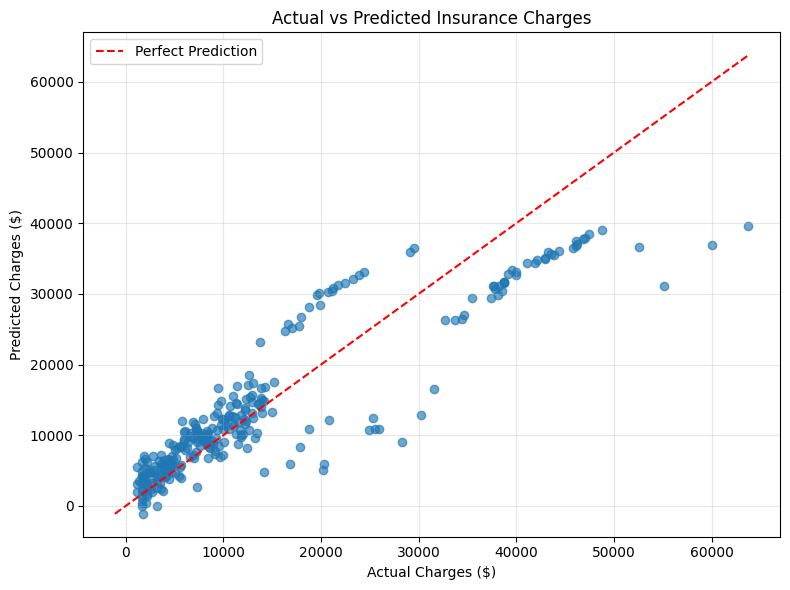

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.65)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Insurance Charges")
plt.xlabel("Actual Charges ($)")
plt.ylabel("Predicted Charges ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()


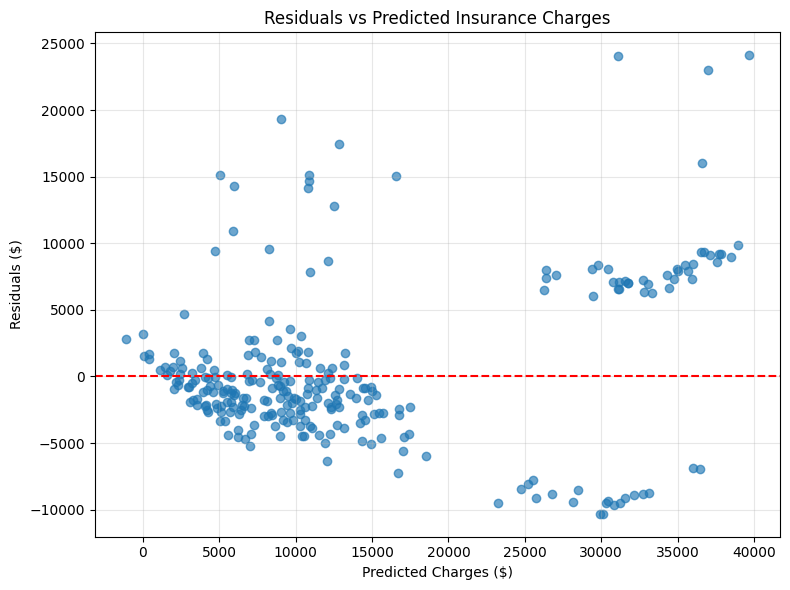

In [41]:
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.65)
plt.axhline(0, color="red", linestyle="--")

plt.title("Residuals vs Predicted Insurance Charges")
plt.xlabel("Predicted Charges ($)")
plt.ylabel("Residuals ($)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("residual_plot.png", dpi=300, bbox_inches="tight")
plt.show()